#### Import Libraries

In [11]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import numpy as np
import time

In [2]:
# Import from the starter file
from lab04_starter import make_recall_batch, RecallNet, train_recall

#### Benchmark Table

In [3]:
configs = [
    ("Plain RNN", "rnn", None),
    ("LSTM (default)", "lstm", None),
    ("LSTM (bias=3)", "lstm", 3.0),
    ("GRU (default)", "gru", None),
    ("GRU (bias=3)", "gru", 3.0),
]

In [4]:
seq_lens = [10, 30, 60]
seeds = [0, 1, 2]
print("--- BENCHMARK RESULTS ---")
for name, kind, g_bias in configs:
    for seq_len in seq_lens:
        accs = []
        for seed in seeds:
            acc, _ = train_recall(kind, seq_len=seq_len, seed=seed, gate_bias=g_bias)
            accs.append(acc)
        mean_acc = sum(accs) / len(accs)
        print(f"Config: {name:15s} | Seq Len: {seq_len:2d} | Seeds: {[f'{a:.3f}' for a in accs]} | Mean: {mean_acc:.3f}")

--- BENCHMARK RESULTS ---
Config: Plain RNN       | Seq Len: 10 | Seeds: ['0.491', '1.000', '0.495'] | Mean: 0.662
Config: Plain RNN       | Seq Len: 30 | Seeds: ['0.248', '0.251', '0.264'] | Mean: 0.254
Config: Plain RNN       | Seq Len: 60 | Seeds: ['0.250', '0.240', '0.233'] | Mean: 0.241
Config: LSTM (default)  | Seq Len: 10 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000
Config: LSTM (default)  | Seq Len: 30 | Seeds: ['0.248', '0.251', '0.255'] | Mean: 0.251
Config: LSTM (default)  | Seq Len: 60 | Seeds: ['0.249', '0.251', '0.254'] | Mean: 0.251
Config: LSTM (bias=3)   | Seq Len: 10 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000
Config: LSTM (bias=3)   | Seq Len: 30 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000
Config: LSTM (bias=3)   | Seq Len: 60 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000
Config: GRU (default)   | Seq Len: 10 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000
Config: GRU (default)   | Seq Len: 30 | Seeds: ['0.241', '0.257', '0.254'] | Mean: 0

#### Gradient-through-time measurement

In [5]:
def measure_gradients(kind, gate_bias=None, seeds=[0, 1, 2, 3, 4], seq_len=60):
    hidden = 32
    batch_size = 16
    all_grad_norms = []
    
    for seed in seeds:
        torch.manual_seed(seed)
        generator = torch.Generator().manual_seed(seed + 100)
        model = RecallNet(kind, hidden=hidden, gate_bias=gate_bias)
        model.zero_grad()
        
        x, y = make_recall_batch(batch_size, seq_len, generator)
        x.requires_grad_()
        
        out, _ = model.rnn(x)
        logits = model.head(out[:, -1])
        loss = nn.functional.cross_entropy(logits, y)
        loss.backward()
        
        grad = x.grad.abs().mean(dim=(0, 2)).detach().cpu().numpy()
        all_grad_norms.append(grad)
        
    return np.median(all_grad_norms, axis=0)

### Measure required models

In [6]:
grads_rnn = measure_gradients("rnn", None)
grads_lstm_default = measure_gradients("lstm", None)
grads_lstm_bias3 = measure_gradients("lstm", 3.0)

#### Plot

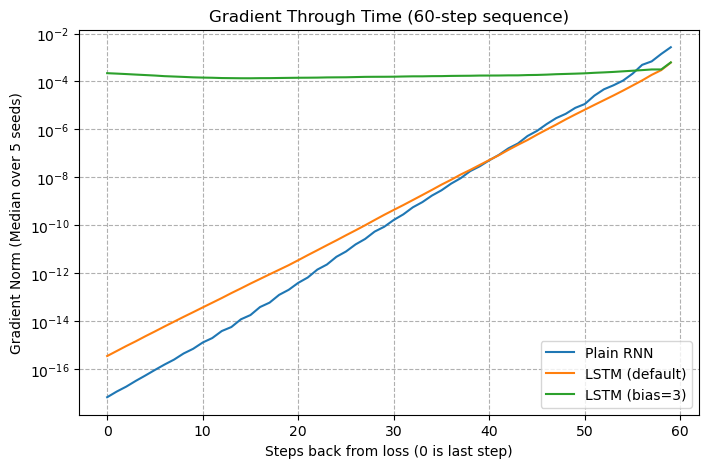

In [7]:
plt.figure(figsize=(8, 5))
plt.plot(grads_rnn, label="Plain RNN")
plt.plot(grads_lstm_default, label="LSTM (default)")
plt.plot(grads_lstm_bias3, label="LSTM (bias=3)")
plt.yscale("log")
plt.xlabel("Steps back from loss (0 is last step)")
plt.ylabel("Gradient Norm (Median over 5 seeds)")
plt.title("Gradient Through Time (60-step sequence)")
plt.legend()
plt.grid(True, which="both", ls="--")
plt.savefig("gradient_plot.png")
plt.show()

In [8]:
steps_to_check = [0, 9, 29, 59]
print("Steps back:", steps_to_check)
print("Plain RNN gradients:       ", [f"{grads_rnn[s]:.5f}" for s in steps_to_check])
print("LSTM default gradients:    ", [f"{grads_lstm_default[s]:.5f}" for s in steps_to_check])
print("LSTM bias=3 gradients:     ", [f"{grads_lstm_bias3[s]:.5f}" for s in steps_to_check])

Steps back: [0, 9, 29, 59]
Plain RNN gradients:        ['0.00000', '0.00000', '0.00000', '0.00269']
LSTM default gradients:     ['0.00000', '0.00000', '0.00000', '0.00061']
LSTM bias=3 gradients:      ['0.00022', '0.00015', '0.00016', '0.00063']


#### Controlled Fixes Script

In [9]:
print("--- PART A: FORGET-BIAS SWEEP ---")
for b in [0, 1, 2, 3]:
    accs = [train_recall("lstm", seq_len=30, seed=s, gate_bias=float(b))[0] for s in [0, 1, 2]]
    print(f"LSTM Forget Bias {b} | Seeds: {[f'{a:.3f}' for a in accs]} | Mean: {sum(accs)/len(accs):.3f}")

print("\n--- PART B: CLIPPING COMPARISON ---")
for clip_val, label in [(1.0, "Clipping ON (1.0)"), (None, "Clipping OFF (None)")]:
    accs = [train_recall("rnn", seq_len=30, seed=s, clip=clip_val)[0] for s in [0, 1, 2]]
    print(f"Plain RNN | {label:20s} | Seeds: {[f'{a:.3f}' for a in accs]} | Mean: {sum(accs)/len(accs):.3f}")

--- PART A: FORGET-BIAS SWEEP ---
LSTM Forget Bias 0 | Seeds: ['0.247', '0.251', '0.258'] | Mean: 0.252
LSTM Forget Bias 1 | Seeds: ['0.495', '0.496', '1.000'] | Mean: 0.664
LSTM Forget Bias 2 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000
LSTM Forget Bias 3 | Seeds: ['1.000', '1.000', '1.000'] | Mean: 1.000

--- PART B: CLIPPING COMPARISON ---
Plain RNN | Clipping ON (1.0)    | Seeds: ['0.248', '0.251', '0.264'] | Mean: 0.254
Plain RNN | Clipping OFF (None)  | Seeds: ['0.248', '0.251', '0.264'] | Mean: 0.254


#### Timing Limits Script

In [12]:
print("--- TIMING LIMITS ---")
for length in [50, 100, 200, 400]:
    times = []
    for _ in range(3):
        model = RecallNet("lstm", hidden=32, gate_bias=3.0)
        optimizer = torch.optim.Adam(model.parameters(), lr=3e-3)
        x, y = make_recall_batch(64, length, torch.Generator().manual_seed(0))
        
        start = time.time()
        optimizer.zero_grad()
        loss = torch.nn.functional.cross_entropy(model(x), y)
        loss.backward()
        optimizer.step()
        end = time.time()
        
        times.append(end - start)
    print(f"Sequence Length {length:3d} | Best Time: {min(times):.4f} seconds")

--- TIMING LIMITS ---
Sequence Length  50 | Best Time: 0.0148 seconds
Sequence Length 100 | Best Time: 0.0240 seconds
Sequence Length 200 | Best Time: 0.0429 seconds
Sequence Length 400 | Best Time: 0.0874 seconds
